# 08 · Thermal management of a fuel-cell aircraft

A PEM fuel cell turns roughly half of the hydrogen energy into electricity. The rest is heat at
only ~80 °C, which has to be rejected to air that may be 40 °C on a hot day. Tutorial 07 showed
how much heat the stack produces. This tutorial asks **what that heat costs the aircraft**: in
heat-exchanger mass, in pump power, and in ram-air drag.

PhlyGreen has two thermal-management (TMS) models:

- **Class I**: exchanger mass = peak heat / specific power (5 kW/kg here). One line, no drag.
- **Class II**: a geometric model. The coolant leaving the stack first warms the liquid hydrogen
  fuel, then rejects the rest to ram air. Each heat exchanger is sized from its geometry (tube
  banks or plate-fin), the coolant pump is an electrical load on the fuel cell, and the ram-air
  duct adds drag.

We look at:

1. the **heat to reject** along the mission;
2. **Class I vs Class II** on the same aircraft;
3. **inside Class II**: where the heat goes and which exchangers carry it;
4. the **ε-NTU method**, and why the ram-air exchanger is the big one;
5. the **exchanger geometry**, to scale;
6. the **design point**: which flight condition sizes the hardware;
7. the **ram-air duct**: the trade between exchanger mass and drag.

The Class-II design takes about a minute. It needs CoolProp. See also the user guide page
*Thermal Management*.

In [1]:
import sys, os
sys.path.insert(0, os.getcwd())            # tutorials/ (when run from here)
from _learning_utils import add_examples_to_path
add_examples_to_path()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import PhlyGreen as pg
from PhlyGreen.config import TMSConfig
from PhlyGreen.Systems.Thermal import effectiveness, FlowArrangement
from PhlyGreen.Systems.Thermal.plotting import draw_hex, plot_tms_rating
import common

def design(tms_class):
    cfg = common.hydrogen_config()               # the ATR 42-600-based hydrogen aircraft
    cfg.tms = TMSConfig(tms_class=tms_class)
    a = pg.build_aircraft()
    a.configure(cfg)
    return a

ac1 = design("I")            # Class I: specific-power TMS
ac2 = design("II")           # Class II: geometric TMS (~1 min)
tms, res = ac2.tms, ac2.weight.tms_result
print(f"Class I : WTO = {ac1.weight.WTO:,.0f} kg, TMS = {ac1.weight.WHeat_Exchanger:,.0f} kg")
print(f"Class II: WTO = {ac2.weight.WTO:,.0f} kg, TMS = {ac2.weight.WHeat_Exchanger:,.0f} kg")

Class I : WTO = 21,727 kg, TMS = 955 kg
Class II: WTO = 22,386 kg, TMS = 1,114 kg


## 1 · The heat to reject

`Mission` records the fuel-cell heat at the take-off point (worst-case take-off / one-engine-out
power, not flown by the profile) and at the peak of every flown segment:
`mission.thermal_profile`. The heat the coolant must reject is the gap between the
thermo-neutral voltage and the cell voltage. For this 80 °C, 1.5 bar stack nearly all the product
water leaves as vapour, so the thermo-neutral voltage is close to 1.25 V (tutorial 07, §8).

Note the ratio of heat to electrical power: at a design cell voltage of 0.5 V the stack rejects
**more heat than it delivers electricity**.

product-water vapour fraction x_v = 1.00; fuel-cell rating 4,021 kW
peak heat 4,963 kW = 1.23 x the fuel-cell electrical rating


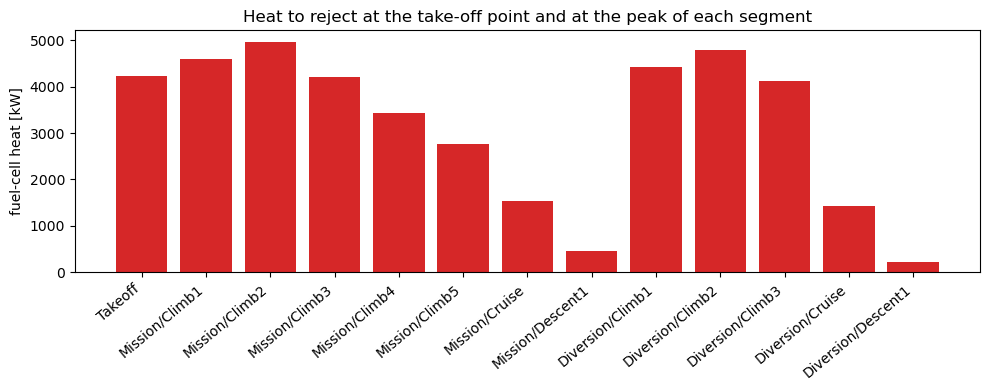

In [2]:
prof = ac2.mission.thermal_profile
names = [p["name"] for p in prof]
Q = np.array([p["Q_fc"] for p in prof]) / 1e3
fc = ac2.fuelcell
print(f"product-water vapour fraction x_v = {fc.x_vapour:.2f}; fuel-cell rating {fc.P_fc_rated/1e3:,.0f} kW")
print(f"peak heat {Q.max():,.0f} kW = {Q.max()*1e3/fc.P_fc_rated:.2f} x the fuel-cell electrical rating")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(names, Q, color="tab:red")
ax.set_ylabel("fuel-cell heat [kW]")
ax.set_title("Heat to reject at the take-off point and at the peak of each segment")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right"); plt.tight_layout(); plt.show()

## 2 · Class I vs Class II

Both close the same aircraft. Class I divides the peak heat by a single specific power. Class II
builds the actual hardware, and adds two couplings back into the design: the **pump power**
(the fuel cell must supply it, so it burns hydrogen and grows the stack) and the **ram-air drag**
(a drag-coefficient increment on the polar). Both feed the take-off-weight snowball.

In [3]:
rows = []
for name, a in (("Class I", ac1), ("Class II", ac2)):
    w = a.weight
    rows.append((name, w.WTO, w.WHeat_Exchanger, w.WPT, w.WH2_Fuel + w.WTank, w.WStructure,
                 a.fuelcell.P_fc_rated / 1e3, a.fuelcell.P_aux_tms / 1e3, a.aerodynamics.extra_Cd))
print(f"{'':9s}{'WTO':>8s}{'TMS':>7s}{'FC sys':>8s}{'H2+tank':>9s}{'struct':>8s}{'FC kW':>8s}{'pump kW':>9s}{'ΔCd':>9s}")
for r in rows:
    print(f"{r[0]:9s}{r[1]:8.0f}{r[2]:7.0f}{r[3]:8.0f}{r[4]:9.0f}{r[5]:8.0f}{r[6]:8.0f}{r[7]:9.1f}{r[8]:9.5f}")
print(f"\nheat per kg of TMS: Class I {max(ac1.mission.Max_FC_Thermal_Pwr, ac1.mission.TO_FC_Thermal_Pwr)/ac1.weight.WHeat_Exchanger/1e3:.1f} kW/kg, "
      f"Class II {Q.max()/ac2.weight.WHeat_Exchanger:.1f} kW/kg")

              WTO    TMS  FC sys  H2+tank  struct   FC kW  pump kW      ΔCd
Class I     21727    955    2410     1345   11934    3871      0.0  0.00000
Class II    22386   1114    2500     1414   12274    4021     32.5  0.00000

heat per kg of TMS: Class I 5.0 kW/kg, Class II 4.5 kW/kg


The geometric model gives a heavier TMS than the 5 kW/kg rule of thumb (4.5 kW/kg here), plus a
pump. With the default ideal intake the duct produces no net drag (see §7 for a realistic one). The extra TMS mass then snowballs: a heavier aircraft needs a larger
fuel cell, which produces more heat. Published fuel-cell aircraft studies use about 2–7 kW/kg for
the heat exchangers, so neither number is wrong by itself; the point of Class II is that the number
comes out of the physics and the mission, not from an assumption.

## 3 · Inside Class II: where the heat goes

The coolant leaves the stack at `T_op`. It first warms the liquid hydrogen on its way to the
stack: the hydrogen arrives as a saturated liquid at ~22 K, so it absorbs its latent heat plus
~300 K of warming. That is a free heat sink, but a small one (under 10 % of the heat here). The reactants entering the stack
below `T_op` absorb a little more. **Everything else must go to ram air.**

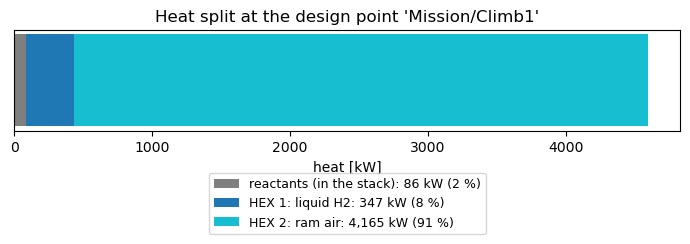

role                 units  family             kg/unit  L/unit total kg
coolant_to_h2            1  plate_fin              3.9     9.3        4
coolant_to_ram_air      32  finned_tube_bank      33.2    49.1     1063
pump + motor                                                         47   (32.5 kW)


In [4]:
hb = res.heat_balance
parts = {"reactants (in the stack)": hb["reactants"], "HEX 1: liquid H2": hb["HEX H2"],
         "HEX 2: ram air": hb["HEX ram air"]}
fig, ax = plt.subplots(figsize=(7, 3))
left = 0
for (k, v), c in zip(parts.items(), ("tab:gray", "tab:blue", "tab:cyan")):
    ax.barh([0], [v / 1e3], left=left, color=c, label=f"{k}: {v/1e3:,.0f} kW ({100*v/hb['stack']:.0f} %)")
    left += v / 1e3
ax.set_yticks([]); ax.set_xlabel("heat [kW]")
ax.set_title(f"Heat split at the design point '{res.design_point['name']}'")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=1, fontsize=9)
plt.tight_layout(); plt.show()

print(f"{'role':20s}{'units':>6s}  {'family':18s}{'kg/unit':>8s}{'L/unit':>8s}{'total kg':>9s}")
for u in res.units:
    print(f"{u.role:20s}{u.n_parallel:6d}  {u.design.family:18s}{u.design.weight:8.1f}"
          f"{u.design.volume*1e3:8.1f}{u.mass:9.0f}")
print(f"{'pump + motor':20s}{'':6s}  {'':18s}{'':8s}{'':8s}{res.pump_mass:9.0f}   ({res.pump_power/1e3:.1f} kW)")

Each role uses as many identical units in parallel as needed to keep one unit under the per-unit
mass and volume caps (50 kg and 50 L by default). Many small units is how such a heat exchanger
would be packaged in nacelles and fairings.

## 4 · ε-NTU: why the ram-air exchanger is the big one

An exchanger's **effectiveness** ε is the heat it transfers divided by the most it could
transfer, `C_min (T_hot,in − T_cold,in)`. To reach a given ε it needs a certain number of
transfer units, `NTU = U A / C_min`. Area grows with NTU, and NTU grows steeply as ε approaches
its ceiling.

For the ram-air exchanger the driving temperature difference is small: coolant at ~80 °C
against air at the free-stream total temperature. Asking the air to heat up by 50 K therefore
means a high effectiveness, hence a large area.

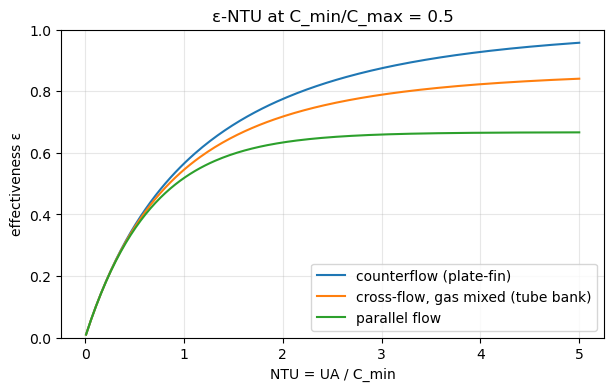

design point: coolant enters the ram-air HEX at 79.2 °C, air at 10.3 °C (total temperature)
the air is asked to heat by 50 K out of 69 K available -> ε ≈ 0.73


In [5]:
ntu = np.linspace(0.01, 5, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for arr, lab in ((FlowArrangement.COUNTERFLOW, "counterflow (plate-fin)"),
                 (FlowArrangement.CROSSFLOW_CMIN_MIXED, "cross-flow, gas mixed (tube bank)"),
                 (FlowArrangement.PARALLEL, "parallel flow")):
    ax.plot(ntu, [effectiveness(n, 0.5, arr) for n in ntu], label=lab)
ax.set_xlabel("NTU = UA / C_min"); ax.set_ylabel("effectiveness ε"); ax.set_ylim(0, 1)
ax.set_title("ε-NTU at C_min/C_max = 0.5"); ax.grid(alpha=0.3); ax.legend()
plt.show()

cond = tms._conditions(res.design_point)
T0 = cond["T_amb"] + cond["V_inf"]**2 / 2010.0
T_cool = cond["T_op"] - hb["HEX H2"] / (res.mdot_coolant * tms._coolant(cond["T_op"], 1.0).cp)
dT_air = min(tms.ram_air_delta_T, tms.ram_air_max_effectiveness * (T_cool - T0))
print(f"design point: coolant enters the ram-air HEX at {T_cool-273.15:.1f} °C, air at {T0-273.15:.1f} °C "
      f"(total temperature)")
print(f"the air is asked to heat by {dT_air:.0f} K out of {T_cool-T0:.0f} K available -> ε ≈ {dT_air/(T_cool-T0):.2f}")

## 5 · The exchanger geometry, to scale

`draw_hex` draws one unit of each role from its sized layout: the front cross-section (the tube
pattern with its annular fins, or the plate-fin layer stack), the face or top view, and a summary.
The geometry is built so that the coolant and the air flow at typical design velocities; the area
then sets the depth of the bank.

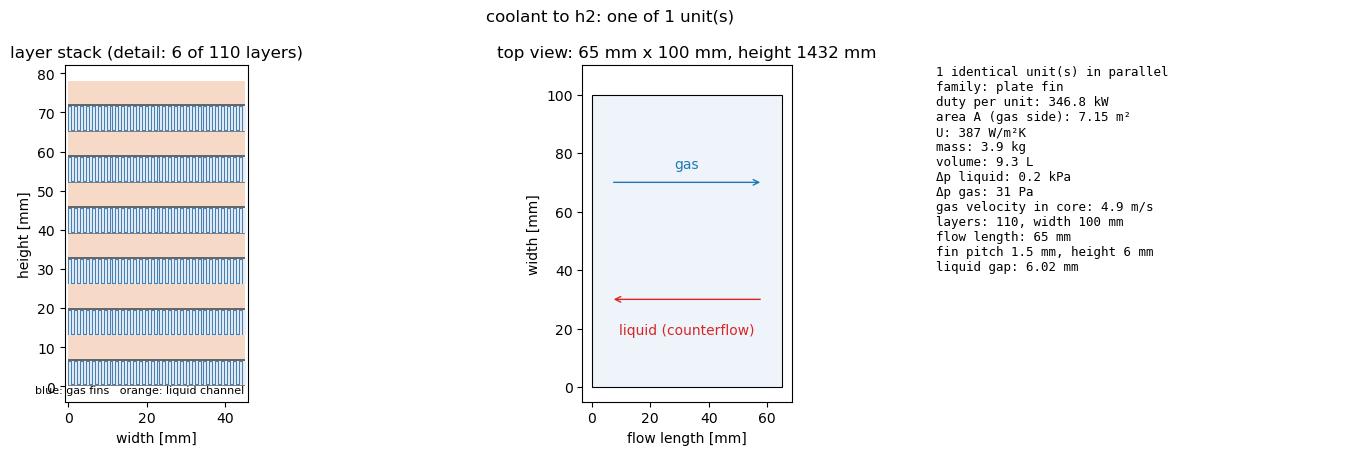

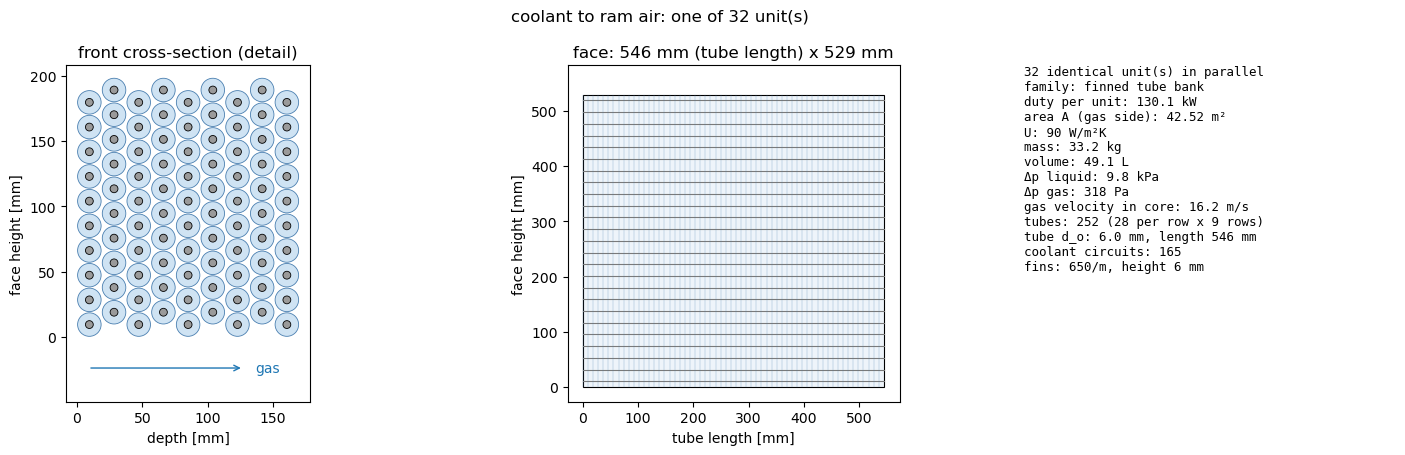

In [6]:
for u in res.units:
    draw_hex(u.design, n_parallel=u.n_parallel,
             title=f"{u.role.replace('_', ' ')}: one of {u.n_parallel} unit(s)")
    plt.show()

## 6 · Which flight condition sizes the TMS?

The hardware must reject the heat **at every point of the mission**, not just where the heat
peaks. A low-speed point has little ram air; a high point has cold, thin air. PhlyGreen tries
every point carrying at least half of the peak heat as the design point, sizes the hardware
there, **rates** that fixed hardware at every other point (same pump flow, same intake area), and
keeps the lightest design that never falls short.

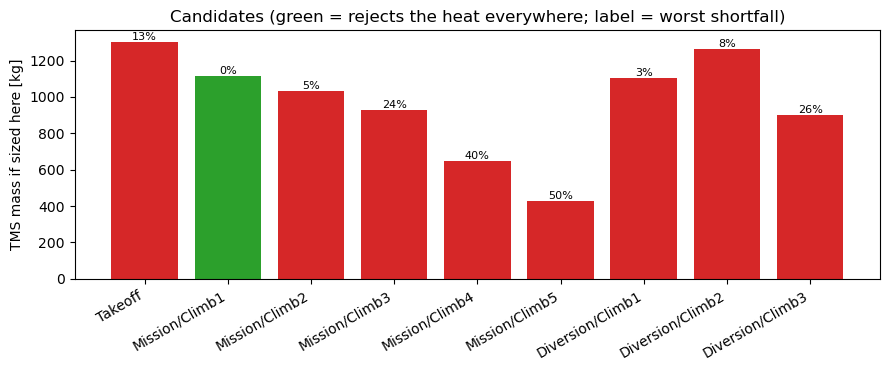

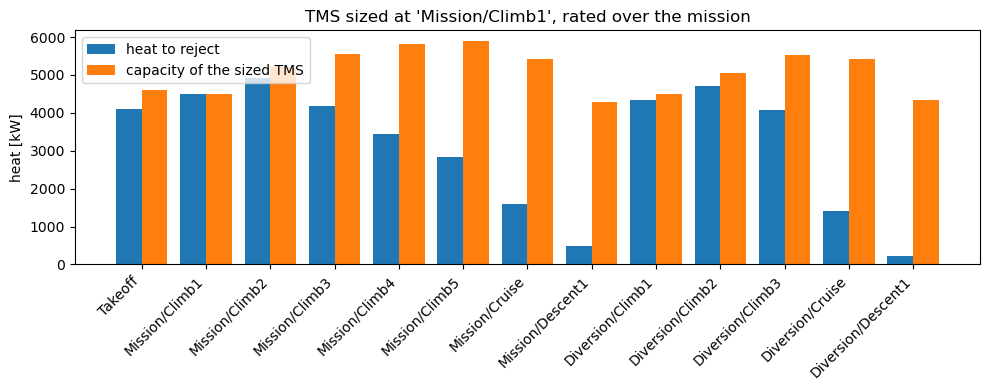

In [7]:
cand = res.candidates
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([c["point"] for c in cand], [c["mass"] for c in cand],
       color=["tab:green" if c["feasible"] else "tab:red" for c in cand])
for i, c in enumerate(cand):
    ax.text(i, c["mass"], f"{100*c['worst_shortfall']:.0f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("TMS mass if sized here [kg]")
ax.set_title("Candidates (green = rejects the heat everywhere; label = worst shortfall)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_tms_rating(tms, res, prof, ax=ax); plt.tight_layout(); plt.show()

The chosen design point is a **slow** point: the first climb segment, at low speed and high heat.
A heavier design is not automatically safe: the take-off design is the heaviest candidate, yet it
falls short at the first climb, because its intake was sized at the higher take-off speed. The
lighter candidates, sized at faster or higher points, fall short there too.

## 7 · The ram-air duct: exchanger mass vs drag

How much should the air heat up? A **large** temperature rise needs little air (a small intake,
low drag) but a high effectiveness, hence a heavy exchanger. A **small** rise needs a lot of air
(more drag) but a light exchanger. We sweep the design air temperature rise at the design point.

The drag depends on how much of the dynamic pressure the intake recovers. With an ideal intake
(the default, a lower bound), heating the air can even produce a small thrust (Meredith effect);
here we use 90 % recovery.

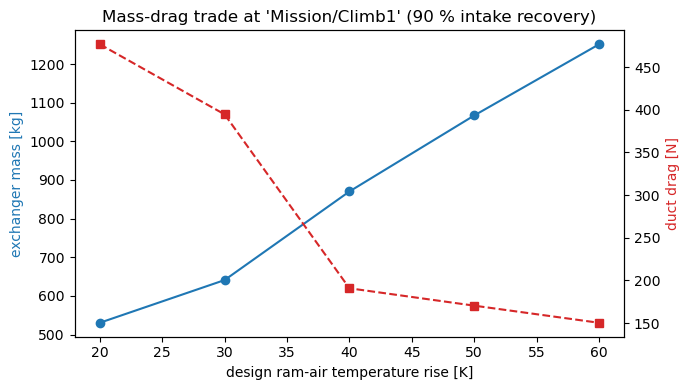

ΔT_air  20 K: ram air  207.0 kg/s, exchangers    530 kg, drag    477 N
ΔT_air  30 K: ram air  138.0 kg/s, exchangers    641 kg, drag    395 N
ΔT_air  40 K: ram air  103.5 kg/s, exchangers    870 kg, drag    191 N
ΔT_air  50 K: ram air   82.8 kg/s, exchangers   1067 kg, drag    170 N
ΔT_air  60 K: ram air   75.0 kg/s, exchangers   1251 kg, drag    150 N


In [8]:
point = res.design_point
tms.ram_recovery = 0.9
dTs = [20, 30, 40, 50, 60]
mass, drag, mdot = [], [], []
for dT in dTs:
    tms.ram_air_delta_T = dT
    r = tms.SizeAtPoint(point)
    mass.append(r.hex_mass); drag.append(r.ram_drag); mdot.append(r.mdot_ram_air)
tms.ram_air_delta_T, tms.ram_recovery = 50.0, 1.0           # restore the defaults

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dTs, mass, "o-", color="tab:blue"); ax.set_ylabel("exchanger mass [kg]", color="tab:blue")
ax.set_xlabel("design ram-air temperature rise [K]")
ax2 = ax.twinx(); ax2.plot(dTs, drag, "s--", color="tab:red"); ax2.set_ylabel("duct drag [N]", color="tab:red")
ax2.grid(False)
ax.set_title(f"Mass-drag trade at '{point['name']}' (90 % intake recovery)")
plt.tight_layout(); plt.show()
for dT, m_, d_, md_ in zip(dTs, mass, drag, mdot):
    print(f"ΔT_air {dT:3d} K: ram air {md_:6.1f} kg/s, exchangers {m_:6.0f} kg, drag {d_:6.0f} N")

Neither end is free. Which one is better depends on how the aircraft values a kilogram against a
newton of drag over the whole mission: that is an aircraft-level question, which is why the TMS
belongs inside the sizing loop and not in a separate spreadsheet.

## Takeaways

- A fuel cell rejects **about as much heat as it delivers power**, at a low temperature. The
  driving temperature difference to ambient air is small, so the ram-air exchangers are large.
- The cryogenic hydrogen is a useful but **small** heat sink (under 10 % of the heat).
- A geometric TMS model gives a mass that **follows from the physics and the mission**. It also
  adds a pump and ram-air drag, and all three feed the weight snowball.
- The TMS is sized by the flight condition where heat is high **and** cooling air is scarce,
  usually a slow point, not necessarily the point with the most heat.
- Exchanger mass and duct drag trade against each other through the air temperature rise. The
  intake quality (ram recovery) decides whether the duct costs drag at all.

## Questions for students

1. Why is a 80 °C heat source harder to cool than a gas turbine's oil or a 300 °C exhaust?
2. Why does the design point end up at a slow point of the mission rather than at the peak heat?
3. Is a lighter heat exchanger always better? Use the mass–drag sweep to argue for a choice.

## Suggested modifications

- **Hotter coolant at take-off.** Set `TMSConfig(tms_class="II", takeoff_coolant_overtemperature=15)`.
  Does it matter for this aircraft? (Look at which point sizes the TMS.)
- **Coolant temperature drop.** Change `coolant_delta_t` (default 10 K) and watch the pump power
  and the exchanger mass move in opposite directions.
- **Design cell voltage.** Rerun with `common.hydrogen_config(v_cell_design=0.6)`. Less heat per
  kW, but a heavier stack (tutorial 07, §4). Where is the optimum now?
- **Per-unit caps.** Raise `max_weight_per_unit` / `max_volume_per_unit`: fewer, larger units.

## Limitations to keep in mind

The exchanger mass is core-only (no headers, ducts, piping or coolant), there is no hot-day
sizing yet, and the motor/inverter losses are not yet heat sources. These are listed in the
project's next steps.

---
*These tutorials are educational. The TMS numbers come from PhlyGreen's Class-II model with its
default inputs, none of them calibrated against flight hardware — read the user guide before
quoting a figure.*